In [1]:
import torchvision
print(torchvision.__version__)

0.29.1+cpu


In [ ]:
import torchvision

dataset = torchvision.datasets.Flowers102(
    root="./data",        # saves to flower_classifier/data/
    split="train",
    download=True         # downloads automatically if not present
)

In [ ]:
print(f"Number of training images: {len(dataset)}")
print(f"Sample: {dataset[0]}")

Number of training images: 1020
Sample: (<PIL.Image.Image image mode=RGB size=754x500 at 0x233F7453DD0>, 0)


In [ ]:
val_dataset = torchvision.datasets.Flowers102(root="./data", split="val", download=True)
test_dataset = torchvision.datasets.Flowers102(root="./data", split="test", download=True)

print(f"Val: {len(val_dataset)}")
print(f"Test: {len(test_dataset)}")

Val: 1020
Test: 6149


In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader

# Transforms
train_transforms = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

val_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Reload datasets with transforms
train_dataset = torchvision.datasets.Flowers102(root="./data", split="train", transform=train_transforms)
val_dataset   = torchvision.datasets.Flowers102(root="./data", split="val",   transform=val_transforms)
test_dataset  = torchvision.datasets.Flowers102(root="./data", split="test",  transform=val_transforms)

# Dataloaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=32, shuffle=False, num_workers=2)

print("Dataloaders ready!")

Dataloaders ready!


In [ ]:
import torch
import torch.nn as nn
from torchvision import models

# Load pretrained EfficientNet-B0
model = models.efficientnet_b0(weights="IMAGENET1K_V1")

# Replace final layer (1000 → 102 classes)
model.classifier[1] = nn.Linear(1280, 102)

# Move to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

print(f"Using device: {device}")
print("Model ready!")

Using device: cpu
Model ready!


In [ ]:
# Freeze base layers (only train the new head first)
for param in model.features.parameters():
    param.requires_grad = False

# Loss function and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=0.001)

print("Ready to train!")

Ready to train!


In [ ]:
# Train head only (5 epochs)
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

    train_acc = 100. * correct / total

    # Validation
    model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100. * val_correct / val_total
    print(f"Epoch {epoch+1}/{epochs} | Loss: {running_loss/len(train_loader):.3f} | Train Acc: {train_acc:.1f}% | Val Acc: {val_acc:.1f}%")

print("Phase 1 done!")

Epoch 1/5 | Loss: 4.366 | Train Acc: 12.1% | Val Acc: 53.1%
Epoch 2/5 | Loss: 3.238 | Train Acc: 60.9% | Val Acc: 72.6%
Epoch 3/5 | Loss: 2.481 | Train Acc: 74.7% | Val Acc: 77.7%
Epoch 4/5 | Loss: 1.933 | Train Acc: 80.8% | Val Acc: 81.5%
Epoch 5/5 | Loss: 1.611 | Train Acc: 84.9% | Val Acc: 82.7%
Phase 1 done!


In [ ]:
# Unfreeze all layers
for param in model.features.parameters():
    param.requires_grad = True

# Lower learning rate for fine-tuning
optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

# Fine-tune (10 epochs)
epochs = 10
best_val_acc = 0.0

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

    train_acc = 100. * correct / total

    # Validation
    model.eval()
    val_correct = 0
    val_total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = outputs.max(1)
            val_correct += predicted.eq(labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100. * val_correct / val_total
    print(f"Epoch {epoch+1}/{epochs} | Loss: {running_loss/len(train_loader):.3f} | Train Acc: {train_acc:.1f}% | Val Acc: {val_acc:.1f}%")

    # Save best model
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "flower_model.pth")
        print(f"  ✓ Best model saved ({val_acc:.1f}%)")

print(f"Training done! Best val acc: {best_val_acc:.1f}%")

Epoch 1/10 | Loss: 1.146 | Train Acc: 87.4% | Val Acc: 87.0%
  ✓ Best model saved (87.0%)
Epoch 2/10 | Loss: 0.830 | Train Acc: 88.8% | Val Acc: 88.3%
  ✓ Best model saved (88.3%)
Epoch 3/10 | Loss: 0.653 | Train Acc: 90.4% | Val Acc: 90.0%
  ✓ Best model saved (90.0%)
Epoch 4/10 | Loss: 0.533 | Train Acc: 92.9% | Val Acc: 91.5%
  ✓ Best model saved (91.5%)
Epoch 5/10 | Loss: 0.457 | Train Acc: 94.3% | Val Acc: 91.6%
  ✓ Best model saved (91.6%)
Epoch 6/10 | Loss: 0.389 | Train Acc: 94.7% | Val Acc: 92.2%
  ✓ Best model saved (92.2%)
Epoch 7/10 | Loss: 0.335 | Train Acc: 96.3% | Val Acc: 91.8%
Epoch 8/10 | Loss: 0.289 | Train Acc: 96.5% | Val Acc: 92.3%
  ✓ Best model saved (92.3%)
Epoch 9/10 | Loss: 0.289 | Train Acc: 95.9% | Val Acc: 93.1%
  ✓ Best model saved (93.1%)
Epoch 10/10 | Loss: 0.261 | Train Acc: 95.9% | Val Acc: 92.7%
Training done! Best val acc: 93.1%


In [ ]:
import os
print(os.path.exists("flower_model.pth"))

True


Predicted class: 53
Predicted flower: sunflower


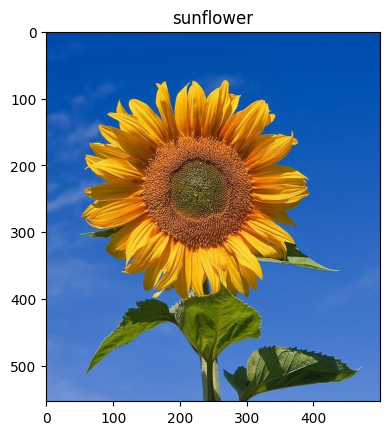

In [ ]:
import requests
from PIL import Image
from io import BytesIO
import matplotlib.pyplot as plt

# Load image from URL
url = "https://imgs.search.brave.com/2MEAAH-YV4KX838MrdwBo56o4ICtNyrilQ7gogArjnU/rs:fit:500:0:0:0/g:ce/aHR0cHM6Ly91cGxv/YWQud2lraW1lZGlh/Lm9yZy93aWtpcGVk/aWEvY29tbW9ucy90/aHVtYi80LzQwL1N1/bmZsb3dlcl9za3lf/YmFja2Ryb3AuanBn/LzI1MHB4LVN1bmZs/b3dlcl9za3lfYmFj/a2Ryb3AuanBnP3V0/bV9zb3VyY2U9ZW4u/d2lraXBlZGlhLm9y/ZyZ1dG1fY2FtcGFp/Z249cGFyc2VyJnV0/bV9jb250ZW50PXRo/dW1ibmFpbA"
response = requests.get(url)
img = Image.open(BytesIO(response.content)).convert("RGB")

# Apply transforms
input_tensor = val_transforms(img).unsqueeze(0).to(device)

flower_names = {
    0: "pink primrose", 1: "hard-leaved pocket orchid", 2: "canterbury bells",
    3: "sweet pea", 4: "english marigold", 5: "tiger lily", 6: "moon orchid",
    7: "bird of paradise", 8: "monkshood", 9: "globe thistle", 10: "snapdragon",
    11: "colt's foot", 12: "king protea", 13: "spear thistle", 14: "yellow iris",
    15: "globe-flower", 16: "purple coneflower", 17: "peruvian lily", 18: "balloon flower",
    19: "giant white arum lily", 20: "fire lily", 21: "pincushion flower", 22: "fritillary",
    23: "red ginger", 24: "grape hyacinth", 25: "corn poppy", 26: "prince of wales feathers",
    27: "stemless gentian", 28: "artichoke", 29: "sweet william", 30: "carnation",
    31: "garden phlox", 32: "love in the mist", 33: "mexican aster", 34: "alpine sea holly",
    35: "ruby-lipped cattleya", 36: "cape flower", 37: "great masterwort", 38: "siam tulip",
    39: "lenten rose", 40: "barbeton daisy", 41: "daffodil", 42: "sword lily",
    43: "poinsettia", 44: "bolero deep blue", 45: "wallflower", 46: "marigold",
    47: "buttercup", 48: "oxeye daisy", 49: "common dandelion", 50: "petunia",
    51: "wild pansy", 52: "primula", 53: "sunflower", 54: "pelargonium",
    55: "bishop of llandaff", 56: "gaura", 57: "geranium", 58: "orange dahlia",
    59: "pink-yellow dahlia", 60: "cautleya spicata", 61: "japanese anemone",
    62: "black-eyed susan", 63: "silverbush", 64: "californian poppy", 65: "osteospermum",
    66: "spring crocus", 67: "bearded iris", 68: "windflower", 69: "tree poppy",
    70: "gazania", 71: "azalea", 72: "water lily", 73: "rose", 74: "thorn apple",
    75: "morning glory", 76: "passion flower", 77: "lotus", 78: "toad lily",
    79: "anthurium", 80: "frangipani", 81: "clematis", 82: "hibiscus", 83: "columbine",
    84: "desert-rose", 85: "tree mallow", 86: "magnolia", 87: "cyclamen",
    88: "watercress", 89: "canna lily", 90: "hippeastrum", 91: "bee balm",
    92: "ball moss", 93: "foxglove", 94: "bougainvillea", 95: "camellia",
    96: "mallow", 97: "mexican petunia", 98: "bromelia", 99: "blanket flower",
    100: "trumpet creeper", 101: "blackberry lily"
}

# Predict
model.eval()
with torch.no_grad():
    output = model(input_tensor)
    _, predicted = output.max(1)

print(f"Predicted class: {predicted.item()}")

# Show image

print(f"Predicted flower: {flower_names[predicted.item()]}")
plt.imshow(img)
plt.title(flower_names[predicted.item()])
plt.show()

The part where we start Gradio for hosting API and for making websites out of it

In [ ]:
import gradio as gr

In [ ]:
def classify_flower(image):
    image = image.convert("RGB")
    input_tensor = val_transforms(image).unsqueeze(0).to(device)
    
    with torch.no_grad():
        output = model(input_tensor)
        probabilities = torch.nn.functional.softmax(output[0], dim=0)
    
    top5_prob, top5_idx = torch.topk(probabilities, 5)
    return {flower_names [idx.item()]: float(prob.item()) for prob, idx in zip(top5_prob, top5_idx)}

demo = gr.Interface(
    fn=classify_flower,  
    inputs=gr.Image(type="pil"),
    outputs=gr.Label(),
    
)

demo.launch()

#demo.launch(share = True)

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
